#### Requirements

In [35]:
import pandas as pd
import numpy as np

import sys
sys.path.append("../..")

from src.backtester import calculate_return, backtester
from src.strategies import run_momentum_strategy, generate_momentum_signal
from src.summary import summary

In [ ]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252
returns_array = np.array(returns)

In [37]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, lookback, 0.001)
momentum_signal = generate_momentum_signal(prices, lookback)
momentum_position = momentum_df["position"]

#### Structure - Exploratory Analysis

In [38]:
def analyse_runs(run):

    short = 0
    medium = 0
    long = 0

    short_days = 0
    medium_days = 0
    long_days = 0
    
    for i in range(len(run)):
        if run[i] <= 10:
            short += 1
            short_days += int(run[i])
        elif 10 < run[i] <= 100:
            medium += 1
            medium_days += int(run[i])
        else:
            long += 1
            long_days += int(run[i])

    return {
    "short_runs": short,
    "medium_runs": medium,
    "long_runs": long,
    "short_days": short_days,
    "medium_days": medium_days,
    "long_days": long_days
}

In [39]:
run_boundaries = []

run_boundaries.append(lookback + 1)

for i in range(lookback + 2, len(momentum_position)):
    if momentum_position.iloc[i] != momentum_position.iloc[i - 1]:
        run_boundaries.append(i)

run_boundaries.append(len(momentum_position))

run_boundaries

[253,
 271,
 272,
 552,
 553,
 556,
 557,
 558,
 562,
 568,
 570,
 572,
 573,
 863,
 864,
 866,
 867,
 870,
 875,
 876,
 2020,
 2049,
 2050,
 2455,
 2957,
 2959,
 2994,
 2996,
 3009,
 3012,
 3114,
 3116,
 3122,
 3123,
 3124,
 3125,
 3935,
 3938,
 3941,
 3945,
 3946,
 3948,
 3953,
 3958,
 3959,
 3962,
 4017,
 4019,
 4026,
 4027,
 4029,
 4074,
 4075,
 4078,
 4079,
 4082,
 4092,
 4094,
 4109,
 4110,
 4113,
 4114,
 4117,
 4124,
 4141,
 4142,
 4146,
 4148,
 4769,
 4803,
 5080,
 5105,
 5106,
 5113,
 5115,
 5118,
 5623,
 5630,
 5631,
 5638,
 5639,
 5641,
 5642,
 5867,
 5869,
 5870,
 5872,
 5874,
 6353,
 6356,
 6713]

In [40]:
run_lengths = []

for i in range(1, len(run_boundaries)):
    difference = float(run_boundaries[i]) - float(run_boundaries[i - 1])

    run_lengths.append(difference)

run_lengths

[18.0,
 1.0,
 280.0,
 1.0,
 3.0,
 1.0,
 1.0,
 4.0,
 6.0,
 2.0,
 2.0,
 1.0,
 290.0,
 1.0,
 2.0,
 1.0,
 3.0,
 5.0,
 1.0,
 1144.0,
 29.0,
 1.0,
 405.0,
 502.0,
 2.0,
 35.0,
 2.0,
 13.0,
 3.0,
 102.0,
 2.0,
 6.0,
 1.0,
 1.0,
 1.0,
 810.0,
 3.0,
 3.0,
 4.0,
 1.0,
 2.0,
 5.0,
 5.0,
 1.0,
 3.0,
 55.0,
 2.0,
 7.0,
 1.0,
 2.0,
 45.0,
 1.0,
 3.0,
 1.0,
 3.0,
 10.0,
 2.0,
 15.0,
 1.0,
 3.0,
 1.0,
 3.0,
 7.0,
 17.0,
 1.0,
 4.0,
 2.0,
 621.0,
 34.0,
 277.0,
 25.0,
 1.0,
 7.0,
 2.0,
 3.0,
 505.0,
 7.0,
 1.0,
 7.0,
 1.0,
 2.0,
 1.0,
 225.0,
 2.0,
 1.0,
 2.0,
 2.0,
 479.0,
 3.0,
 357.0]

In [41]:
cash_runs = run_lengths[::2]
invested_runs = run_lengths[1::2]

In [42]:
run_analysis = analyse_runs(run_lengths)
run_analysis

{'short_runs': 67,
 'medium_runs': 10,
 'long_runs': 13,
 'short_days': 177,
 'medium_days': 286,
 'long_days': 5997}

In [43]:
cash_analysis = analyse_runs(cash_runs)
cash_analysis

{'short_runs': 36,
 'medium_runs': 5,
 'long_runs': 4,
 'short_days': 101,
 'medium_days': 151,
 'long_days': 1200}

In [44]:
invested_analysis = analyse_runs(invested_runs)
invested_analysis

{'short_runs': 31,
 'medium_runs': 5,
 'long_runs': 9,
 'short_days': 76,
 'medium_days': 135,
 'long_days': 4797}

In [45]:
long_cash_runs = []

for i in range(len(cash_runs)):
    if cash_runs[i] > 100:
        long_cash_runs.append(cash_runs[i])

long_cash_runs

[280.0, 290.0, 405.0, 225.0]

In [46]:
long_invested_runs = []

for i in range(len(invested_runs)):
    if invested_runs[i] > 100:
        long_invested_runs.append(invested_runs[i])

long_invested_runs

[1144.0, 502.0, 102.0, 810.0, 621.0, 277.0, 505.0, 479.0, 357.0]

In [47]:
print(np.mean(long_cash_runs), 
      np.median(long_cash_runs), 
      np.mean(long_invested_runs), 
      np.median(long_invested_runs)
      )

300.0 285.0 533.0 502.0


#### Run Length Permutation Random Strategy

In [48]:
def generate_random_signal_v5(prices, lookback):

    momentum_df, _ = run_momentum_strategy(prices, returns, lookback, 0.001)
    momentum_position = momentum_df["position"]

    run_boundaries = []
    
    run_boundaries.append(lookback + 1)
    
    for i in range(lookback + 2, len(momentum_position)):
        if momentum_position.iloc[i] != momentum_position.iloc[i - 1]:
            run_boundaries.append(i)
    
    run_boundaries.append(len(momentum_position))

    run_lengths = []
    
    for i in range(1, len(run_boundaries)):
        difference = float(run_boundaries[i]) - float(run_boundaries[i - 1])
    
        run_lengths.append(difference)

    cash_runs = run_lengths[::2]
    invested_runs = run_lengths[1::2]

    random_cash_sequence = np.random.permutation(cash_runs).astype(int)
    random_invested_sequence = np.random.permutation(invested_runs).astype(int)

    sequence = []
        
    for i in range(len(cash_runs)):
        
        sequence.extend([0] * random_cash_sequence[i])
        sequence.extend([1] * random_invested_sequence[i])
    
    sequence.append(np.nan)
    
    random_signal = ([np.nan] * lookback) + sequence

    return random_signal


In [49]:
def run_simulation_v5(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v5(prices, lookback)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result

In [50]:
np.random.seed(44)

simulation_output = run_simulation_v5(100)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,10.880236,0.101357,0.137969,0.768838,-0.313847,0.322950,0.775232,89
1,5.539611,0.076005,0.161014,0.535479,-0.367422,0.206859,0.775232,89
2,4.644221,0.069842,0.174890,0.473505,-0.536205,0.130252,0.775232,89
3,3.623271,0.061547,0.163593,0.446895,-0.551895,0.111519,0.775232,89
4,3.431431,0.059793,0.172358,0.423175,-0.551895,0.108342,0.775232,89
...,...,...,...,...,...,...,...,...
95,7.107210,0.085062,0.168242,0.569402,-0.551895,0.154127,0.775232,89
96,5.418590,0.075221,0.173463,0.504881,-0.551895,0.136296,0.775232,89
97,4.734200,0.070502,0.163761,0.497846,-0.514815,0.136946,0.775232,89
98,7.615583,0.087639,0.169242,0.581105,-0.516043,0.169829,0.775232,89


Sharpe Average: 0.4824
Sharpe Median:  0.4662
Largest Sharpe: 0.8610
Average No. of Trades: 89.0000
Average Time Invested: 0.7752
Empirical p-value: 0.1089


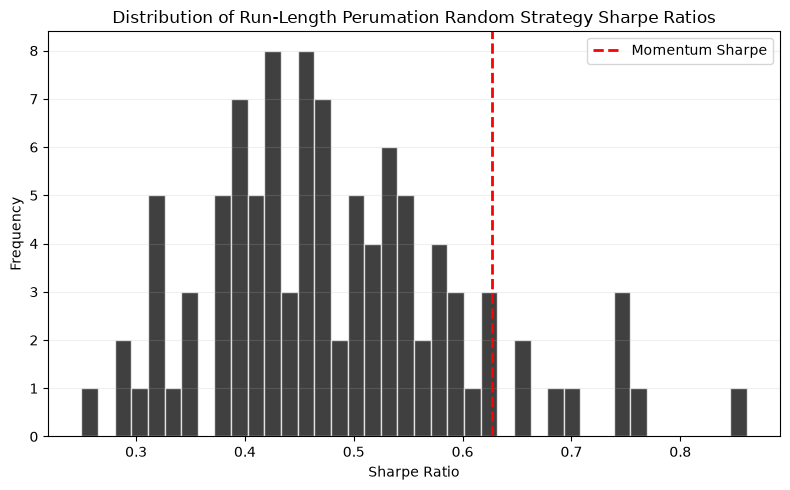

In [51]:
summary(simulation_df, momentum_results, "Distribution of Run-Length Perumation Random Strategy Sharpe Ratios")